##  Simulated Annealing on the 1D Offline Bin Packing Problem

We apply local search techniques to solve the classical one-dimensional offline Bin Packing Problem. In this case, we focus on Simulated Annealing, a metaheuristic known for its ability to escape local optima and explore the solution space effectively.

###  Why Choose Simulated Annealing?

Simulated Annealing is particularly suitable for the 1D Bin Packing Problem because, unlike other local search methods like Best Improvement or Tabu Search, it can probabilistically accept worse solutions. This characteristic allows it to escape local minima and continue searching for better packings, especially when the solution space is complex or deceptive. It balances exploration and exploitation through its temperature-controlled acceptance mechanism.

###  Workflow Overview

1. **Dataset Generation**  
   We generate a synthetic dataset of item sizes, sampled randomly between 1 and 10 units. Each bin has a fixed capacity of 15 units.

2. **Simulated Annealing Function**  
   We implement and execute the Simulated Annealing algorithm, adapted specifically for the Bin Packing Problem.

3. **Data Visualization**  
   We use histograms to visualize the distribution of item sizes, and bar charts to show how items are packed into bins. This helps verify solution feasibility and understand how space is utilized.

4. **Scaling Experiment**  
   We test the algorithm on datasets of increasing size (e.g., 50 to 200 items) to observe how the number of required bins evolves. We aim to detect patterns or relationships between input size and packing efficiency.

This section allows us to evaluate Simulated Annealing not only in terms of performance but also in its ability to adapt to more complex instances.

In [ ]:
# Create the data set 

import numpy as np

def generate_dataset(n_items=100, min_size=1, max_size=10, capacity=15, seed=None):
    rng = np.random.default_rng(seed)
    items = rng.integers(min_size, max_size + 1, size=n_items)
    return items.tolist(), capacity

In [ ]:
# Define teh new simulated annelaing for our bin packing porblem

import numpy as np
import math
import random
import copy

class SimulatedAnnealingBPP:
    def __init__(self, items, capacity, initial_temp=1000.0, final_temp=1.0, alpha=0.95, iterations=100, seed=None):
        self.items = items
        self.capacity = capacity
        self.rng = np.random.default_rng(seed)
        self.initial_temp = initial_temp
        self.final_temp = final_temp
        self.alpha = alpha
        self.iterations = iterations

    def initial_solution(self):
        bins = []
        for item in self.items: # each obkect we want to pack
            placed = False # flag to check if the item is placed
            for b in bins:  # check each bin
                if sum(b) + item <= self.capacity:
                    b.append(item)
                    placed = True
                    break
            if not placed:
                bins.append([item])
        return bins

    def cost(self, bins):
        return len(bins)

    def neighbour(self, bins):
        bins = copy.copy(bins)
        if len(bins) < 2:
            return bins

        # Try moving an item to another bin
        for _ in range(100):  # 100 attempts max
            from_bin = self.rng.integers(len(bins))
            to_bin = self.rng.integers(len(bins))
            if from_bin == to_bin or len(bins[from_bin]) == 0: # skip if same bin or empty
                continue
            item_idx = self.rng.integers(len(bins[from_bin])) # random item to move
            item = bins[from_bin][item_idx] # item to move
            if sum(bins[to_bin]) + item <= self.capacity:
                bins[to_bin].append(item)  # add item to new bin
                del bins[from_bin][item_idx] # remove item from original bin
                if len(bins[from_bin]) == 0:
                    bins.pop(from_bin)
                return bins
        return bins  # return same if no move found

    def accept_probability(self, old_cost, new_cost):
        if new_cost < old_cost:
            return 1.0
        else:
            return math.exp((old_cost - new_cost) / self.temperature)

    def search(self):
        self.temperature = self.initial_temp
        current = self.initial_solution()
        current_cost = self.cost(current)
        best = current
        best_cost = current_cost

        bins_per_iter = []  # nueva lista para seguimiento

        while self.temperature > self.final_temp:
            for _ in range(self.iterations):
                candidate = self.neighbour(current)
                candidate_cost = self.cost(candidate)

                if self.accept_probability(current_cost, candidate_cost) > self.rng.random():
                    current = candidate
                    current_cost = candidate_cost
                    if current_cost < best_cost:
                        best = candidate
                        best_cost = candidate_cost

            bins_per_iter.append(best_cost)  # Save this number for posterior analysis
            self.temperature *= self.alpha

        return best, best_cost, bins_per_iter

In [ ]:
import matplotlib.pyplot as plt

def plot_bin_packing_layout(bins, capacity, title="Bin Configuration - Simulated Annealing"):
    fig, ax = plt.subplots(figsize=(max(6, len(bins)), 5))
    for i, bin in enumerate(bins):
        bottom = 0
        for item in bin:
            ax.bar(i, item, bottom=bottom, color='skyblue', edgecolor='black')
            bottom += item
        ax.text(i, bottom + 0.5, f"{bottom}/{capacity}", ha='center', fontsize=8, color='black')
    ax.set_ylabel("Total Size in Bin")
    ax.set_xlabel("Bin Index")
    ax.set_title(title)
    ax.set_ylim(0, capacity + 10)
    plt.xticks(range(len(bins)))
    plt.tight_layout()
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.show()

In [ ]:
def plot_item_histogram(items):
    plt.figure(figsize=(8, 4))
    plt.hist(items, bins=range(min(items), max(items)+2), edgecolor='black', align='left', rwidth=0.8, color='steelblue')
    plt.xlabel("Item Size")
    plt.ylabel("Frequency")
    plt.title("Histogram of Item Sizes")
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

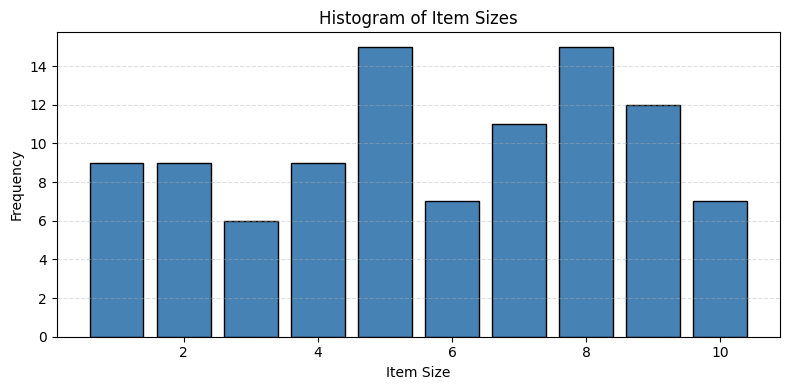

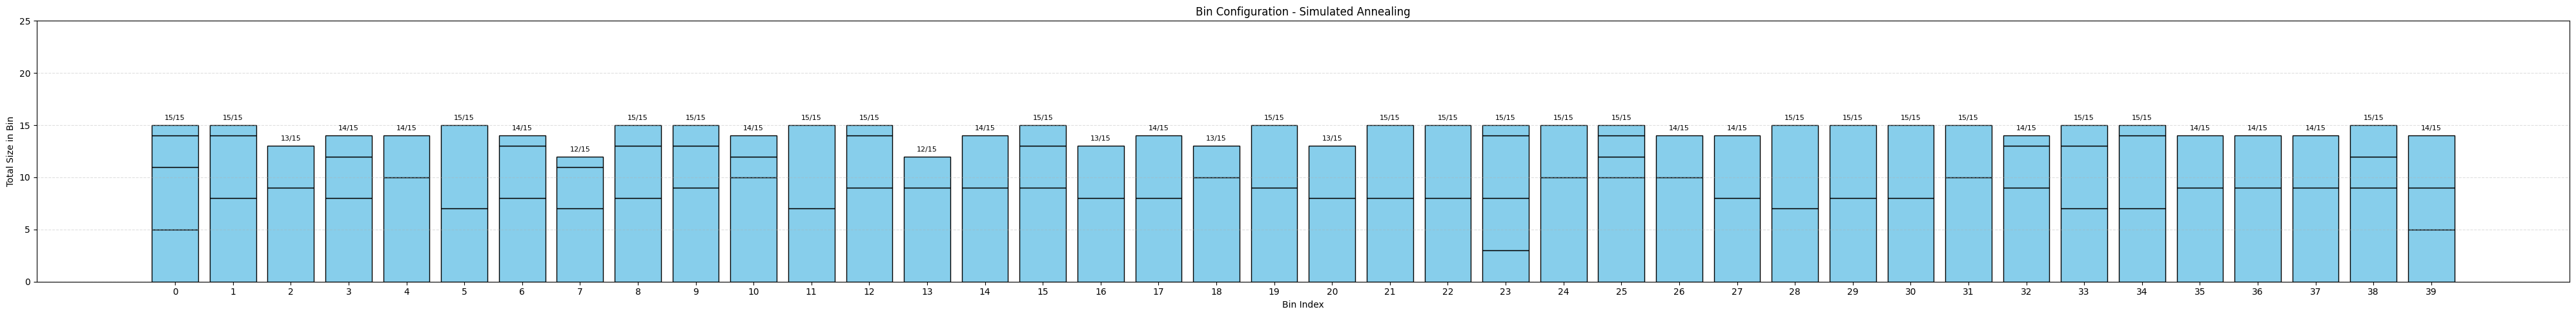

Best number of bins: 40


In [ ]:
items, capacity = generate_dataset(n_items=100, min_size=1, max_size=10, capacity=15, seed=42)

sa_bpp = SimulatedAnnealingBPP(items, capacity)
best_bins, best_cost,_ = sa_bpp.search()
plot_item_histogram(items)

plot_bin_packing_layout(best_bins, capacity)

print(f"Best number of bins: {best_cost}")

Then we try with different number of item and see if there is any linear relationship 

In [ ]:
def evaluate_sa_on_datasets(sizes=[50, 100, 150, 200,250,300], capacity=15, min_item=1, max_item=10, seed=42):
    bins_required = []
    for n_items in sizes:
        items, _ = generate_dataset(n_items=n_items, min_size=min_item, max_size=max_item, capacity=capacity, seed=seed)
        sa_bpp = SimulatedAnnealingBPP(items, capacity, seed=seed)
        _, best_cost,_ = sa_bpp.search()
        bins_required.append(best_cost)
    return sizes, bins_required

import matplotlib.pyplot as plt

def plot_bins_vs_dataset_size(sizes, bins_required):
    plt.figure(figsize=(8, 5))
    plt.plot(sizes, bins_required, marker='o', linestyle='-', color='mediumseagreen')
    plt.xlabel("Number of Items")
    plt.ylabel("Bins Used")
    plt.title("Simulated Annealing: Bins Used vs Dataset Size")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(sizes)
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_bins_vs_dataset_size_with_fit(sizes, bins_required):
    # Ajustar la recta
    m, b = np.polyfit(sizes, bins_required, deg=1)
    fitted = [m * x + b for x in sizes]

    # Crear el gráfico
    plt.figure(figsize=(8, 5))
    plt.plot(sizes, bins_required, marker='o', label='Observed Bins', color='mediumseagreen')
    plt.plot(sizes, fitted, linestyle='--', label=f'Linear Fit: bins ≈ {m:.2f} × items + {b:.2f}', color='gray')
    plt.xlabel("Number of Items")
    plt.ylabel("Bins Used")
    plt.title("Simulated Annealing: Bins Used vs Dataset Size")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return m, b

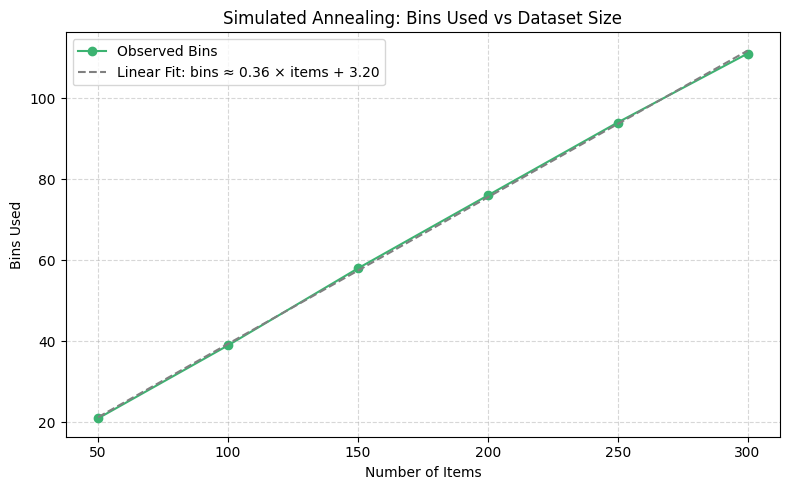

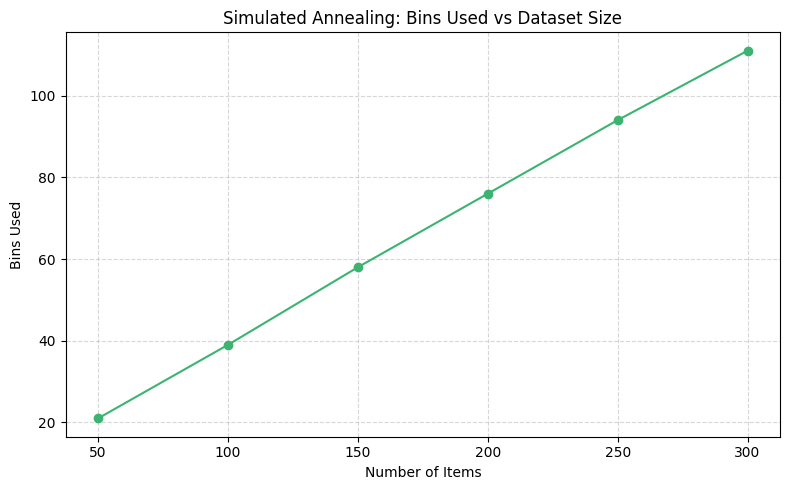

Linear model: bins ≈ 0.36 × items + 3.20


In [ ]:
sizes, bins_required = evaluate_sa_on_datasets()
m, b = plot_bins_vs_dataset_size_with_fit(sizes, bins_required)
plot_bins_vs_dataset_size(sizes, bins_required)
print(f"Linear model: bins ≈ {m:.2f} × items + {b:.2f}")

Try with max size of the bin of 10 instead of 15

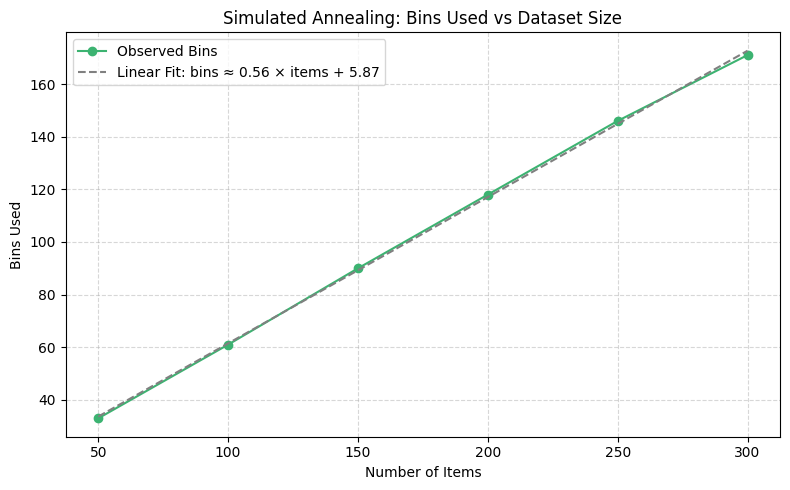

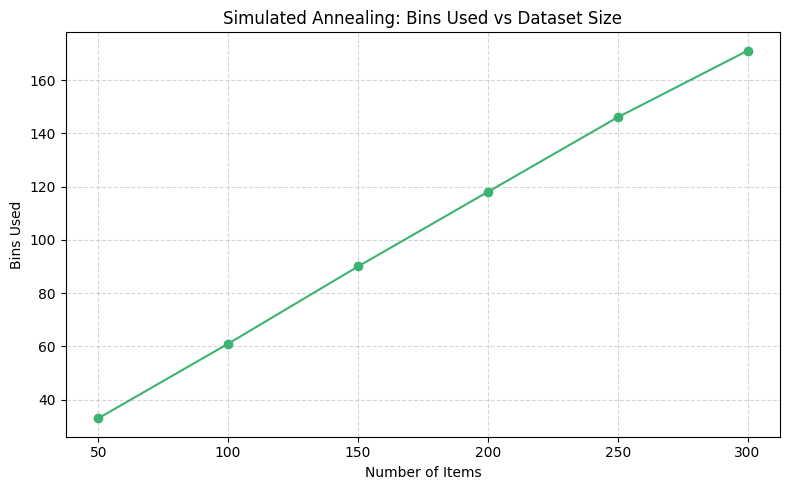

Linear model: bins ≈ 0.56 × items + 5.87


In [ ]:
sizes, bins_required = evaluate_sa_on_datasets(capacity=10)
m, b = plot_bins_vs_dataset_size_with_fit(sizes, bins_required)
plot_bins_vs_dataset_size(sizes, bins_required)
print(f"Linear model: bins ≈ {m:.2f} × items + {b:.2f}")

### 🧬 Genetic Algorithm: Experiments and Analysis

In this section, we apply the Genetic Algorithm to solve the one-dimensional offline Bin Packing Problem using a synthetic dataset. The process includes both qualitative and quantitative analysis of the algorithm's behavior.

#### 1. Initialization
We begin by generating a dataset of items with random weights between 1 and 10 units. Each item must be packed into bins with a fixed capacity of 15 units. The Genetic Algorithm is initialized with a population of feasible solutions constructed using a randomized First Fit heuristic.

#### 2. Visualizing the Dataset
To better understand the instance, we plot a histogram showing the distribution of item weights. This helps us anticipate how challenging the packing problem may be and whether items are likely to fill the bins efficiently.

#### 3. Visualizing the Bin Configuration
After executing the algorithm, we visualize how items are distributed across bins. This allows us to verify feasibility and understand how the algorithm structures the packing, giving insight into which bins are more or less utilized.

#### 4. Scaling the Problem
To study how the algorithm performs as the problem size increases, we run the Genetic Algorithm on datasets with an increasing number of items (e.g., 50, 100, 150, 200). We then plot the number of bins required for each case. This analysis helps us identify whether there is a linear or nonlinear relationship between the number of items and the number of bins used.

This experimental process allows us to assess the robustness and scalability of the Genetic Algorithm under varying levels of complexity.


In [ ]:
import numpy as np
from typing import List, Tuple

class GeneticBPP:
    def __init__(self,
                 items: List[int],
                 capacity: int,
                 pop_size: int = 100, # number of individuals in the population
                 num_generations: int = 300,
                 tournament_size: int = 3,
                 crossover_rate: float = 0.9,
                 mutation_rate: float = 0.2,
                 elitism: bool = True,
                 elite_size: int = 1,
                 seed: int = None):
        
        self.items = items
        self.capacity = capacity
        self.n = len(items)
        self.pop_size = pop_size
        self.num_generations = num_generations
        self.tournament_size = tournament_size
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.elitism = elitism
        self.elite_size = elite_size if elitism else 0
        self.rng = np.random.default_rng(seed)

    def cost(self, solution: List[int]) -> int:
        bins = {}
        #assign items to bins
        for i, bin_id in enumerate(solution): # bin_id is the bin number for item i, enumerate gives us the index
            bins.setdefault(bin_id, []).append(self.items[i])  # item i goes to bin bin_id if not already present

        for bin_contents in bins.values():
            if sum(bin_contents) > self.capacity:
                return float('inf')  # infeasible → penalizado fuertemente
            
        return len(bins)

    def initial_population(self) -> List[List[int]]:
        population = []

        for _ in range(self.pop_size):
            solution = [-1] * self.n
            bin_weights = []  # Actual weight

            for i, item in enumerate(self.items):
                placed = False
                bin_indices = list(range(len(bin_weights)))
                self.rng.shuffle(bin_indices)  # We mix index for randomness

                for j in bin_indices:
                    if bin_weights[j] + item <= self.capacity: # feasibility by construction
                        solution[i] = j
                        bin_weights[j] += item
                        placed = True
                        break

                if not placed:
                    # Open anew bin
                    bin_weights.append(item)
                    solution[i] = len(bin_weights) - 1 # we restart from 0

            population.append(solution)

        return population

    def tournament_selection(self, population: List[List[int]]) -> List[int]:
        contenders = self.rng.choice(population, size=self.tournament_size, replace=False)
        return min(contenders, key=self.cost) # select the best one

    def crossover(self, p1: List[int], p2: List[int]) -> List[int]:
        return [p1[i] if self.rng.random() < 0.5 else p2[i] for i in range(self.n)]

    def mutate(self, solution: List[int]) -> List[int]:
        mutated = solution.copy()
        idx = self.rng.integers(0, self.n) # random index
        mutated[idx] = self.rng.integers(0, self.n) # random bin id
        return mutated

    def search(self) -> Tuple[List[int], int, List[int]]:
        population = self.initial_population()

        # Filtro: asegurarse de tener al menos una solución válida
        population = [ind for ind in population if self.cost(ind) != float('inf')]
        if len(population) == 0:
            raise RuntimeError("Initial population contains no feasible individuals.")

        best_global = None
        cost_global = float('inf')
        bins_per_gen = []  # nueva lista para seguimiento

        for gen in range(self.num_generations):
            population.sort(key=self.cost)

            elites = population[:self.elite_size] if self.elitism else []

            pop_cost = self.cost(population[0])
            if pop_cost != float('inf') and pop_cost < cost_global:
                best_global = population[0].copy()
                cost_global = pop_cost

            bins_per_gen.append(pop_cost)  # guardar evolución del mejor coste en esta generación

            new_population = []

            while len(new_population) < self.pop_size:
                parent1 = self.tournament_selection(population)

                if self.rng.random() < self.crossover_rate:
                    parent2 = self.tournament_selection(population)
                    child = self.crossover(parent1, parent2)
                else:
                    child = parent1.copy()

                if self.rng.random() < self.mutation_rate:
                    child = self.mutate(child)

                new_population.append(child)

            if self.elitism:
                new_population[-self.elite_size:] = elites

            population = new_population

        if best_global is None:
            raise RuntimeError("No feasible solution was found during the search.")

        return best_global, cost_global, bins_per_gen

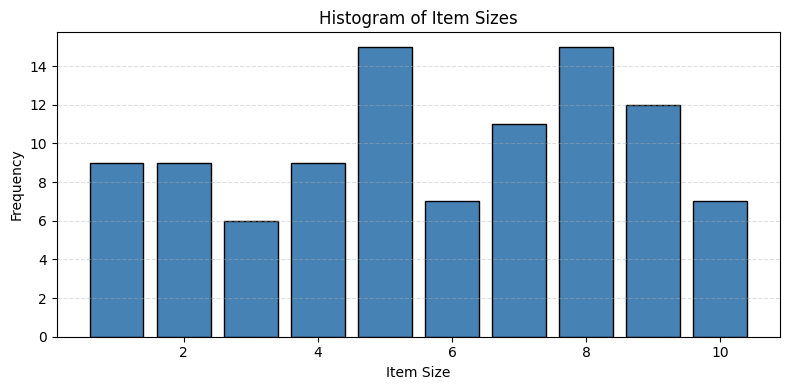

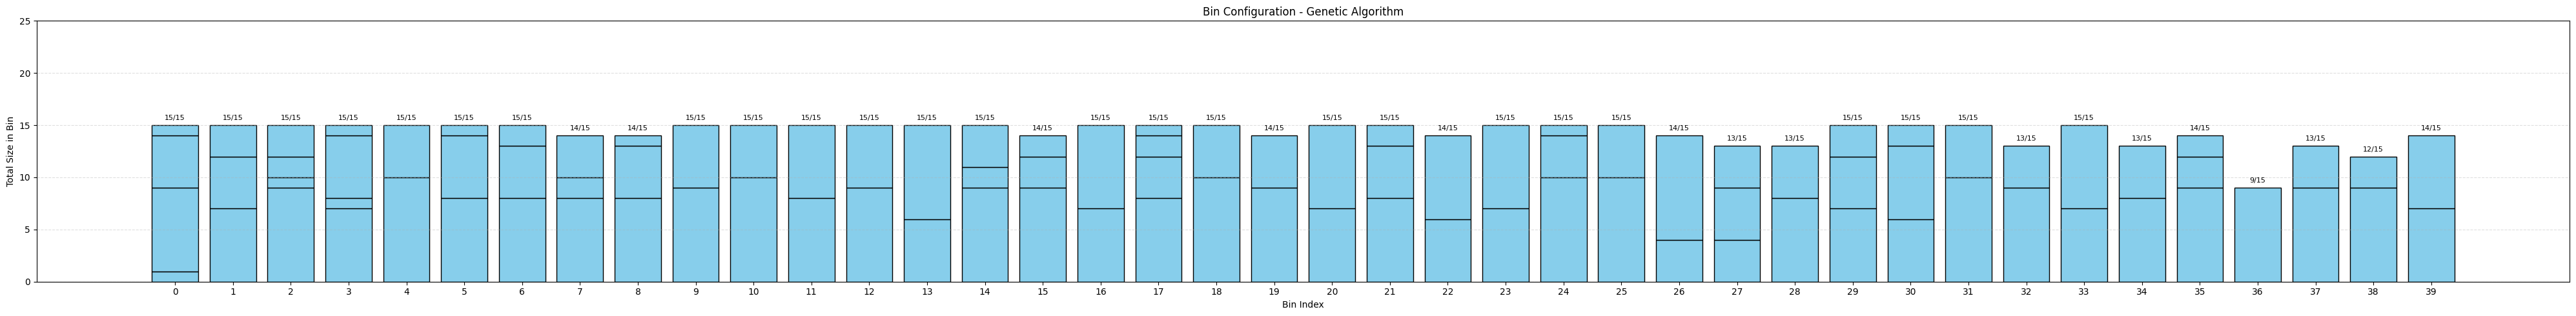

Best number of bins (Genetic Algorithm): 40


In [ ]:
# items, capacity = generate_dataset(n_items=100, min_size=1, max_size=10, capacity=15, seed=42)

ga = GeneticBPP(items, capacity)
best_assignment, best_cost,_ = ga.search()

# 💡 Convertir la asignación en estructura de bins para visualización
def assignment_to_bins(solution, items):
    bins = {}
    for i, bin_id in enumerate(solution):
        bins.setdefault(bin_id, []).append(items[i])
    return [bins[k] for k in sorted(bins)]

best_bins_list = assignment_to_bins(best_assignment, items)

# ✅ REUTILIZACIÓN DIRECTA DE FUNCIONES
plot_item_histogram(items)
plot_bin_packing_layout(best_bins_list, capacity, title="Bin Configuration - Genetic Algorithm")

print(f"Best number of bins (Genetic Algorithm): {best_cost}")

In [ ]:
def evaluate_genetic_on_datasets(sizes=[50, 100, 150, 200, 250, 300],
                                  capacity=15,
                                  min_item=1,
                                  max_item=10,
                                  seed=42,
                                  pop_size=100,
                                  num_generations=300):
    bins_required = []
    for n_items in sizes:
        items, _ = generate_dataset(n_items=n_items, min_size=min_item, max_size=max_item, capacity=capacity, seed=seed)
        ga_bpp = GeneticBPP(items,
                            capacity,
                            pop_size=pop_size,
                            num_generations=num_generations,
                            seed=seed)
        _, best_cost,_ = ga_bpp.search()
        bins_required.append(best_cost)
    return sizes, bins_required

In [ ]:
def plot_bins_vs_dataset_size(sizes, bins_required, title="Bins Used vs Dataset Size"):
    plt.figure(figsize=(8, 5))
    plt.plot(sizes, bins_required, marker='o', linestyle='-', color='mediumseagreen')
    plt.xlabel("Number of Items")
    plt.ylabel("Bins Used")
    plt.title(title)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(sizes)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_bins_vs_dataset_size_with_fit(sizes, bins_required, title="Bins Used vs Dataset Size"):
    m, b = np.polyfit(sizes, bins_required, deg=1)
    fitted = [m * x + b for x in sizes]

    plt.figure(figsize=(8, 5))
    plt.plot(sizes, bins_required, marker='o', label='Observed Bins', color='mediumseagreen')
    plt.plot(sizes, fitted, linestyle='--', label=f'Linear Fit: bins ≈ {m:.2f} × items + {b:.2f}', color='gray')
    plt.xlabel("Number of Items")
    plt.ylabel("Bins Used")
    plt.title(title)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return m, b

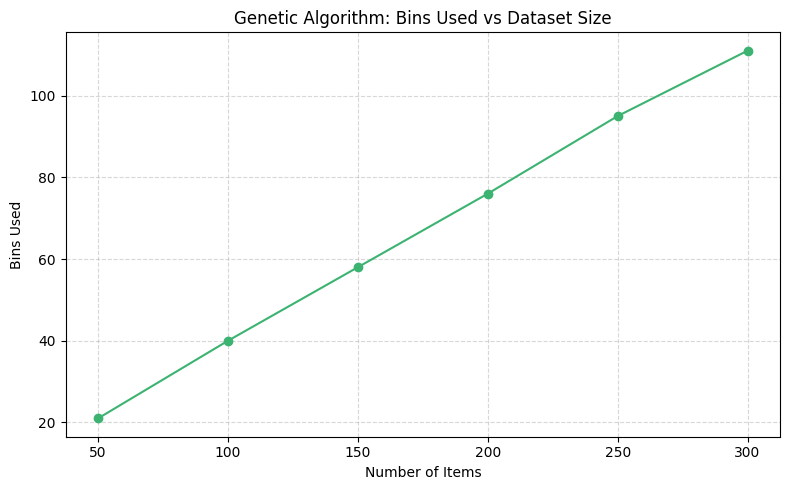

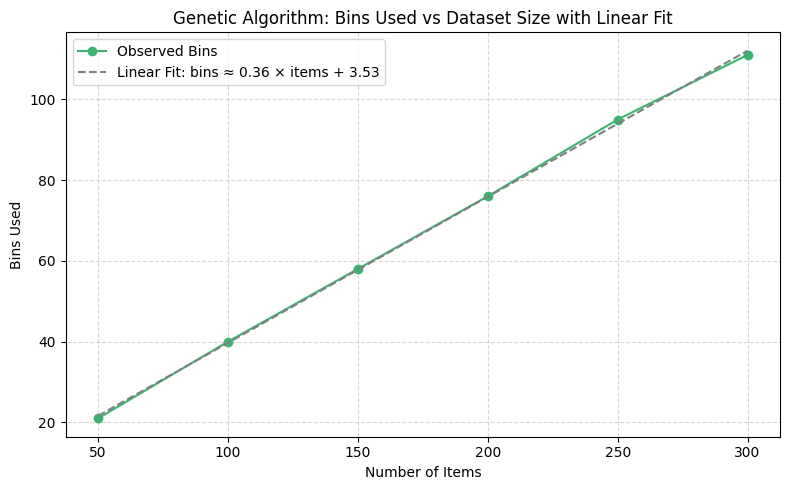

Recta ajustada: bins ≈ 0.36 * items + 3.53


In [ ]:
# Evaluación del algoritmo genético
sizes, bins_ga = evaluate_genetic_on_datasets()

# Visualización simple
plot_bins_vs_dataset_size(sizes, bins_ga, title="Genetic Algorithm: Bins Used vs Dataset Size")

# Visualización con ajuste lineal
m, b = plot_bins_vs_dataset_size_with_fit(sizes, bins_ga, title="Genetic Algorithm: Bins Used vs Dataset Size with Linear Fit")

print(f"Recta ajustada: bins ≈ {m:.2f} * items + {b:.2f}")

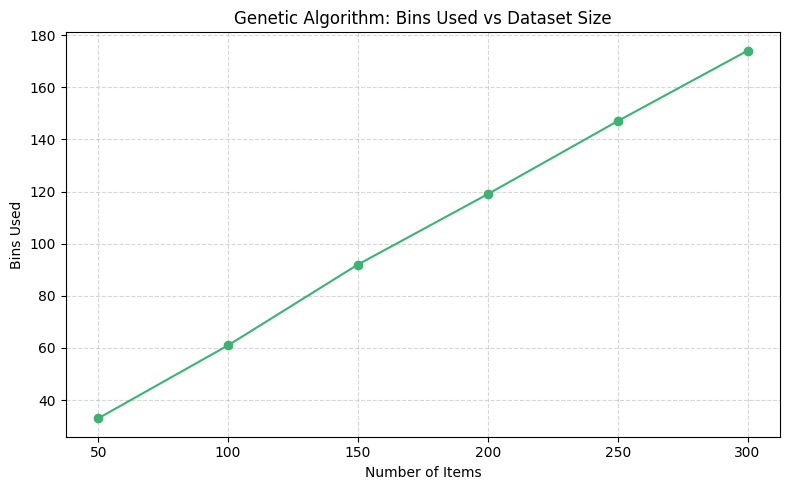

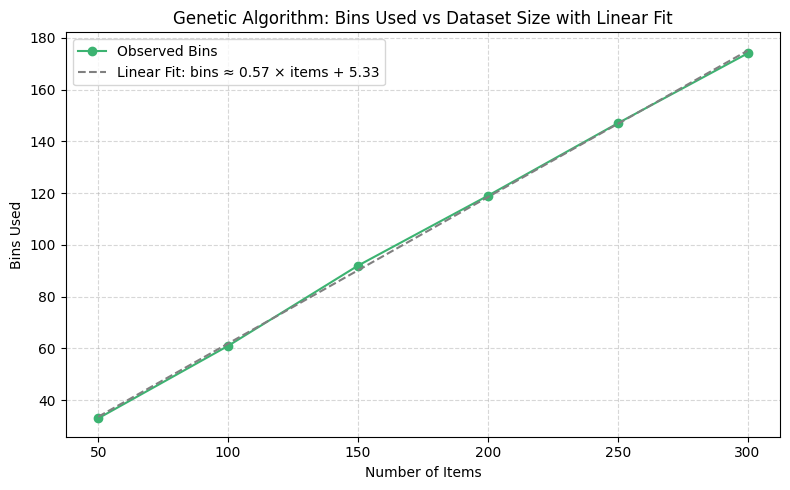

Recta ajustada: bins ≈ 0.57 * items + 5.33


In [ ]:
# Evaluación del algoritmo genético
sizes, bins_ga = evaluate_genetic_on_datasets(capacity=10)

# Visualización simple
plot_bins_vs_dataset_size(sizes, bins_ga, title="Genetic Algorithm: Bins Used vs Dataset Size")

# Visualización con ajuste lineal
m, b = plot_bins_vs_dataset_size_with_fit(sizes, bins_ga, title="Genetic Algorithm: Bins Used vs Dataset Size with Linear Fit")

print(f"Recta ajustada: bins ≈ {m:.2f} * items + {b:.2f}")

## Comparison: Simulated Annealing vs. Genetic Algorithm

In this section, we compare the performance of two metaheuristic approaches — Simulated Annealing (SA) and the Genetic Algorithm (GA) — when applied to the same 1D offline Bin Packing Problem instance.

### What We Are Testing

We run both algorithms under identical conditions:
- Same randomly generated dataset (e.g., 100 items with weights between 1 and 10).
- Same bin capacity (15 units).
- Same initial seed to ensure reproducibility.

We then analyze and visualize:

1. **Final Solution Quality**  
   Number of bins used by each algorithm to complete the packing.

2. **Convergence Behavior**  
   How the number of bins evolves across iterations (SA) or generations (GA). This shows how quickly each algorithm improves and whether it gets stuck in local optima.

3. **Exploration Capability**  
   Whether the algorithm finds better solutions over time or remains trapped in suboptimal regions.

### 🎯 Goal of the Comparison

Our goal is not only to determine which algorithm performs better in terms of final bin usage, but also to understand **how** each algorithm explores the solution space. This comparison highlights the trade-offs between local and population-based search strategies and provides insight into their robustness, convergence, and adaptability.

In [ ]:
def plot_convergence(sa_bins, ga_bins):
    plt.figure(figsize=(8, 5))
    plt.plot(sa_bins, label='Simulated Annealing', color='seagreen')
    plt.plot(ga_bins, label='Genetic Algorithm', color='steelblue')
    plt.xlabel("Iteration / Generation")
    plt.ylabel("Number of Bins")
    plt.title("Convergence Comparison: SA vs GA")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

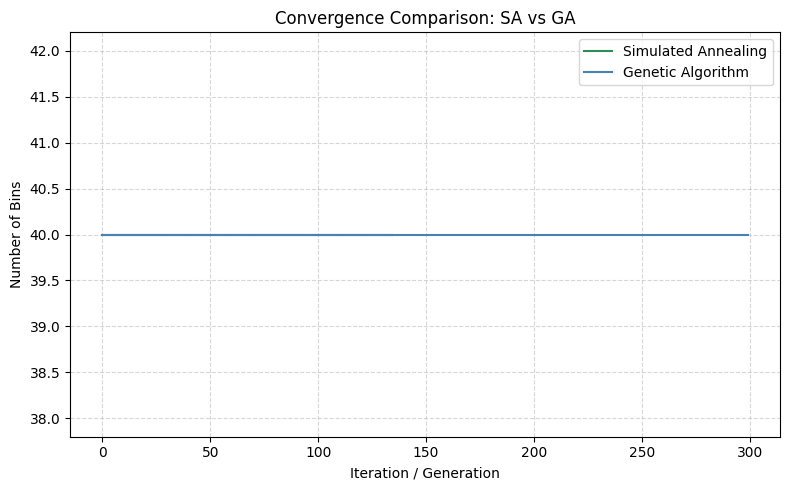

In [ ]:
# Ejecuta ambos algoritmos
_, _, sa_curve = sa_bpp.search()
_, _, ga_curve = ga.search()

# Visualiza comparación
plot_convergence(sa_curve, ga_curve)

###  Why We Increased the Dataset Difficulty

Given that both algorithms consistently converged to the same solution with minimal exploration (especially the Genetic Algorithm), we decided to increase the complexity of the problem instance. The goal was to create a more challenging setting where the differences in search behavior between the algorithms could become more evident.

To do so, we increased the item sizes (e.g., between 8 and 15) and slightly adjusted the bin capacity. This reduces the flexibility of item placement, increases the risk of infeasibility, and forces the algorithms to make smarter decisions in order to minimize the number of bins used.

### We try to vary the data set to a one more complex 

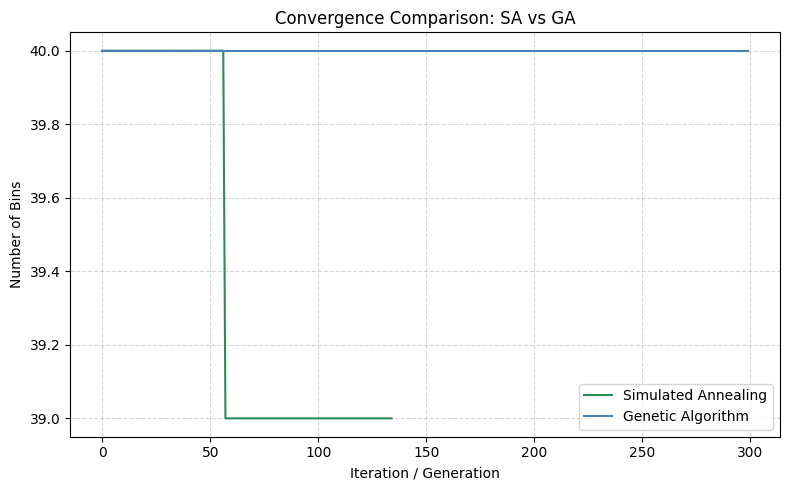

In [ ]:
# Ejemplo más difícil:
items, capacity = generate_dataset(n_items=100, min_size=8, max_size=15, capacity=20)

# Ejecuta ambos algoritmos
_, _, sa_curve = sa_bpp.search()
_, _, ga_curve = ga.search()

# Visualiza comparación
plot_convergence(sa_curve, ga_curve)

### 🧪 Results on the More Challenging Dataset

With the more constrained instance, we observed more meaningful differences between the two algorithms:

- **Genetic Algorithm** maintained a flat convergence line at 40 bins across all generations, indicating it remained stuck in the same local solution and was unable to improve.
  
- **Simulated Annealing** started with 40 bins as well, but around iteration 55 it found a better configuration using only 39 bins and remained stable at that value for the rest of the search.

This confirms that Simulated Annealing’s probabilistic acceptance allows it to explore more diverse regions of the solution space and escape local optima. The experiment highlights how increasing problem difficulty helps reveal the strengths and weaknesses of different metaheuristic strategies.